<a href="https://colab.research.google.com/github/HyeonnWoo/26-2-DIP-202001601/blob/main/notebook_2026/HW08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install nibabel

In [2]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as nd
import scipy.signal as signal


In [3]:
h = nib.load('s02.nii.gz')
mri = h.get_fdata()
print(mri.shape)

(256, 256, 32)


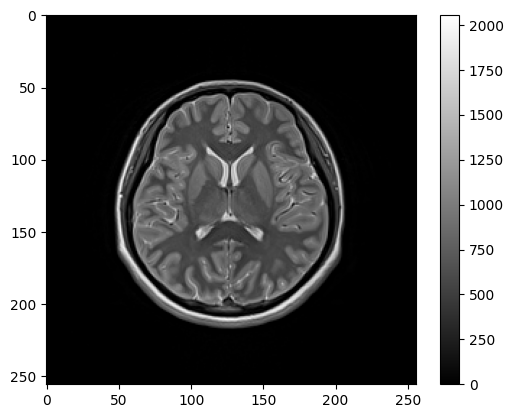

In [4]:
f = mri[::-1,::-1,18].transpose((1,0))
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.show()

## Exerceise 1: Automatic Basic Global Thresholding
- 강의노트의 내용을 기반으로 하여 자동으로 global thresholding을 수행하는 영상처리코드를 작성하고, 적용한 결과를 확인하자.

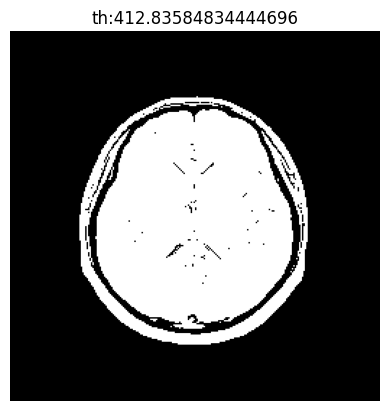

In [5]:
img = f
T_init = 1
T = []
T.append(T_init)
dT = 1000
esp = 5

## write down your algorithm
while dT>esp:
  g1 = img[img > T[-1]]
  g2 = img[img <= T[-1]]

  m1 = np.mean(g1) if len(g1) > 0 else 0
  m2 = np.mean(g2) if len(g2) > 0 else 0

  T_next = (m1 + m2) / 2.0

  dT = np.abs(T_next - T[-1])

  T.append(T_next)

##

bmsk = img>T[-1]
plt.imshow(bmsk,cmap='gray')
plt.axis('off')
plt.title(f'th:{T[-1]}')
plt.show()

## Exercise 2: K-means clustering
- 강의노트의 "standard" k-means clustering algorithm을 완성하여 s02.nii.gz 파일에 적용해보자.
- k=2,3,4 일 때의 결과를 s02.nii.gz에 대해 각각 비교해보자.

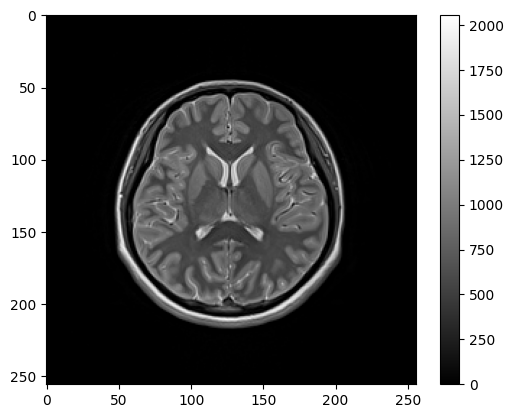

In [ ]:
f = mri[::-1,::-1,18].transpose((1,0))
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.show()

### k = 2 에서의 결과

[ 64. 128.]
[  5.91248043 768.93253625]
[ 13.3779618  806.97810069]
[ 14.87874927 810.79294742]


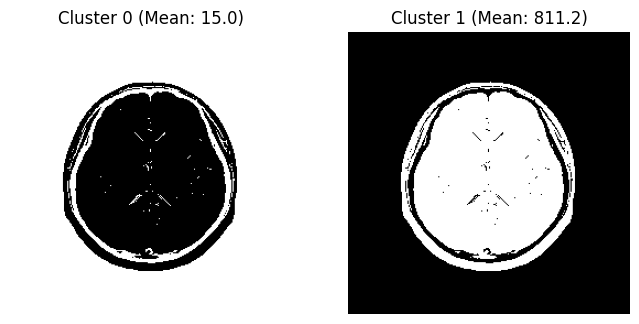

In [6]:
m_vals = np.array([64., 128.])
c = np.zeros((f.shape[0],f.shape[1],len(m_vals)))
cmap = np.zeros_like(f)
m_vals_new = np.zeros(m_vals.shape)
E=10000
eps = 1

while E>eps:
  print(m_vals)

  ## [Standard K-means clustering algorithm]
  for i in range(len(m_vals)):
    c[:, :, i] = np.abs(f - m_vals[i])

  cmap = np.argmin(c, axis=-1)

  for i in range(len(m_vals)):
    mask = (cmap == i)
    if np.sum(mask) > 0:
      m_vals_new[i] = np.mean(f[mask])
    else:
      m_vals_new[i] = m_vals[i]

  E = np.max(np.abs(m_vals_new - m_vals))
  m_vals = m_vals_new.copy()
  ##

# Plot results
plt.figure(figsize=(8, 4))
for i in range(len(m_vals)):
  plt.subplot(1,len(m_vals),i+1)
  plt.imshow(cmap==i,cmap='gray')
  plt.title(f'Cluster {i} (Mean: {m_vals[i]:.1f})')
  plt.axis('off')
plt.show()

### k = 3 에서의 결과

[ 32. 128. 256.]
[  5.71429532 131.61161525 782.55158711]
[  5.58350742 286.42637363 820.42013444]
[  6.56594164 439.36818387 869.77742655]
[  7.77860488 524.78903696 954.65564582]
[   8.88589394  564.7276693  1001.22524942]
[   9.35609253  585.40214503 1026.28635015]
[   9.74585224  600.16392269 1045.00515287]
[   9.96918663  611.14899076 1060.54375458]
[  10.12548702  619.26059252 1072.93304146]
[  10.27753834  626.43959138 1084.57917512]
[  10.4651595   632.87172035 1095.35068609]
[  10.62067308  638.93350227 1106.3679846 ]
[  10.72303659  644.19718628 1116.806307  ]
[  10.81259282  648.81012565 1126.51141846]
[  10.88195991  653.14447674 1136.24891268]
[  11.0008076   657.78103337 1146.96298883]
[  11.09939122  662.22962807 1158.01787017]
[  11.14896588  666.56011892 1169.87836548]
[  11.22010644  670.73786342 1181.81331201]
[  11.32034453  674.68316765 1193.46324144]
[  11.4789024   678.83046015 1205.89238845]
[  11.56606528  682.82459124 1219.42440257]
[  11.63900749  686.6025566

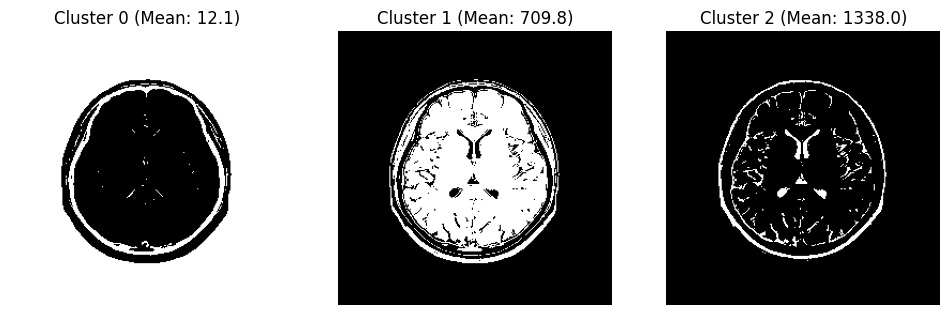

In [7]:
m_vals = np.array([32., 128., 256.])
c = np.zeros((f.shape[0],f.shape[1],len(m_vals)))
cmap = np.zeros_like(f)
m_vals_new = np.zeros(m_vals.shape)
E=10000
eps = 1

while E>eps:
  print(m_vals)

  for i in range(len(m_vals)):
    c[:, :, i] = np.abs(f - m_vals[i])

  cmap = np.argmin(c, axis=-1)

  for i in range(len(m_vals)):
    mask = (cmap == i)
    if np.sum(mask) > 0:
      m_vals_new[i] = np.mean(f[mask])
    else:
      m_vals_new[i] = m_vals[i]

  E = np.max(np.abs(m_vals_new - m_vals))
  m_vals = m_vals_new.copy()

# Plot results
plt.figure(figsize=(12, 4))
for i in range(len(m_vals)):
  plt.subplot(1,len(m_vals),i+1)
  plt.imshow(cmap==i,cmap='gray')
  plt.title(f'Cluster {i} (Mean: {m_vals[i]:.1f})')
  plt.axis('off')
plt.show()

### k = 4 에서의 결과

[ 32.  64. 128. 256.]
[  5.3902956   70.42339833 142.30248307 782.55158711]
[  5.21611091  63.74677419 315.90138161 821.78953569]
[  5.14581205  89.48266423 467.04867345 884.8226079 ]
[  5.37780234 150.08103592 541.70766969 966.18210998]
[   5.68310791  211.62700229  581.4906493  1008.76086527]
[   6.04949301  261.77253521  608.33472236 1037.14429791]
[   6.37167866  303.33477723  629.62413507 1060.54375458]
[   6.66171045  342.59958506  649.90865213 1083.58322112]
[   6.93339546  380.35225376  671.28892794 1108.70843301]
[   7.26295509  420.52176676  697.53134644 1139.86507128]
[   7.58357285  462.37760826  734.06804352 1181.81331201]
[   8.03199188  500.93101793  784.11192458 1243.65063862]
[   8.56485273  525.43305719  826.86716792 1324.14688525]
[   8.88589394  540.50091008  856.88173637 1405.93998309]
[   9.07008524  549.63616483  874.6015902  1456.86222222]
[   9.1876098   555.49710145  885.32087601 1485.68304536]
[   9.23535482  558.52796053  891.07662751 1501.37776517]
[   9.27

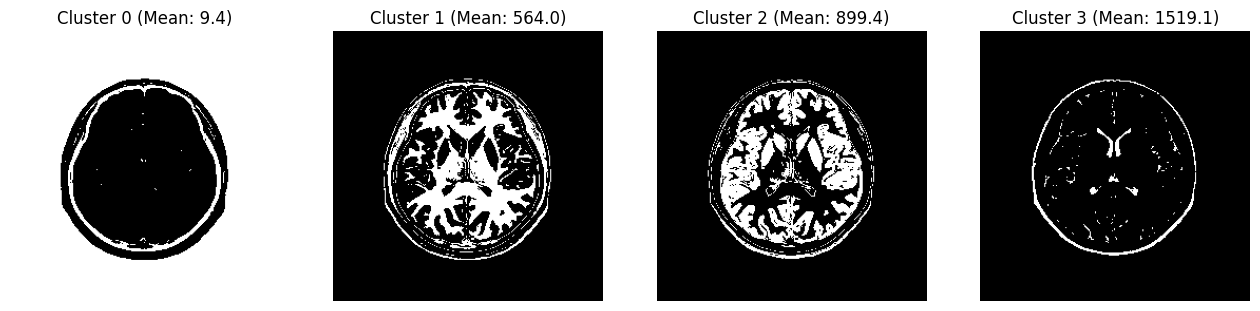

In [8]:
m_vals = np.array([32., 64., 128., 256.])
c = np.zeros((f.shape[0],f.shape[1],len(m_vals)))
cmap = np.zeros_like(f)
m_vals_new = np.zeros(m_vals.shape)
E=10000
eps = 1

while E>eps:
  print(m_vals)

  for i in range(len(m_vals)):
    c[:, :, i] = np.abs(f - m_vals[i])

  cmap = np.argmin(c, axis=-1)

  for i in range(len(m_vals)):
    mask = (cmap == i)
    if np.sum(mask) > 0:
      m_vals_new[i] = np.mean(f[mask])
    else:
      m_vals_new[i] = m_vals[i]

  E = np.max(np.abs(m_vals_new - m_vals))
  m_vals = m_vals_new.copy()

# Plot results
plt.figure(figsize=(16, 4))
for i in range(len(m_vals)):
  plt.subplot(1,len(m_vals),i+1)
  plt.imshow(cmap==i,cmap='gray')
  plt.title(f'Cluster {i} (Mean: {m_vals[i]:.1f})')
  plt.axis('off')
plt.show()